In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.special import gammaln  # for log(y!) = gammaln(y+1)
from scipy.optimize import minimize
from patsy import dmatrix

np.random.seed(2)

TIME_COL = "in Lund C"
BIN_MINUTES = 5
MORNING_START = "05:00:00"
MORNING_END = "11:00:00"

## Loading and Preparing the Data

In [68]:
csv_path = Path("data/Lund_C_20261014_all_commuters.csv")

df = pd.read_csv(csv_path)
print(f"Rows: {len(df):,}")
print("\nColumns:")
print(df.columns.tolist())
print()
print(df["commute_type"].value_counts())

df.head()

Rows: 66,728

Columns:
['worker_id', 'sex', 'residential_municipality', 'workplace_municipality', 'origin_station', 'destination_station', 'desired_arrival', 'commute_type', 'train_to_take', 'waiting_time', 'in Lund C']

commute_type
arrive    39940
leave     26788
Name: count, dtype: int64


,worker_id,sex,residential_municipality,workplace_municipality,origin_station,destination_station,desired_arrival,commute_type,train_to_take,waiting_time,in Lund C
0,1,män,Lessebo,Lund,Lessebo,Lund C,08:42:00,arrive,08:49:00,00:00:00,08:49:00
1,2,män,Lessebo,Lund,Lessebo,Lund C,08:38:00,arrive,08:49:00,00:00:00,08:49:00
2,3,män,Lessebo,Lund,Lessebo,Lund C,08:39:00,arrive,08:49:00,00:00:00,08:49:00
3,4,män,Lessebo,Lund,Lessebo,Lund C,08:30:00,arrive,08:49:00,00:00:00,08:49:00
4,5,män,Tingsryd,Lund,Växjö,Lund C,08:37:00,arrive,07:49:00,00:00:00,07:49:00


## Preparing five minute station-flow counts

The `in Lund C` column gives the simulated station time for both commute directions. We count records in five-minute bins and keep arrivals and departures separate.

In [69]:
# Convert HH:MM:SS to minutes after midnight.
time_parsed = pd.to_datetime(df[TIME_COL], format="%H:%M:%S", errors="coerce")
df = df.loc[time_parsed.notna()].copy()
time_parsed = time_parsed.loc[df.index]

df["minutes_after_midnight"] = (
    time_parsed.dt.hour * 60 + time_parsed.dt.minute + time_parsed.dt.second / 60
)

start_min = 5 * 60
end_min = 11 * 60
morning = df[df["minutes_after_midnight"].between(start_min, end_min, inclusive="left")].copy()

morning["minutes_after_midnight"]

0        529.0
1        529.0
2        529.0
3        529.0
4        469.0
         ...  
66723    516.0
66724    516.0
66725    516.0
66726    516.0
66727    516.0
Name: minutes_after_midnight, Length: 66728, dtype: float64

In [70]:
# Floor each event to its five-minute interval.
morning["bin_minute"] = (
    np.floor(morning["minutes_after_midnight"] / BIN_MINUTES) * BIN_MINUTES
).astype(int)

# Include empty intervals so the time series is continuous.
all_bins = np.arange(start_min, end_min, BIN_MINUTES)
directions = ["arrive", "leave"]
counts = (
    morning.groupby(["commute_type", "bin_minute"])
    .size()
    .rename("count")
    .reset_index()
)

grid = pd.MultiIndex.from_product(
    [directions, all_bins], names=["commute_type", "bin_minute"]
).to_frame(index=False)
counts = grid.merge(counts, on=["commute_type", "bin_minute"], how="left")
counts["count"] = counts["count"].fillna(0).astype(int)
counts["time"] = counts["bin_minute"].map(
    lambda m: f"{int(m // 60):02d}:{int(m % 60):02d}"
)

print(f"Commuters in morning window: {len(morning):,}")
print(counts.groupby("commute_type")["count"].sum())
counts.head()

Commuters in morning window: 66,728
commute_type
arrive    39940
leave     26788
Name: count, dtype: int64


,commute_type,bin_minute,count,time
0,arrive,300,0,05:00
1,arrive,305,0,05:05
2,arrive,310,0,05:10
3,arrive,315,0,05:15
4,arrive,320,0,05:20


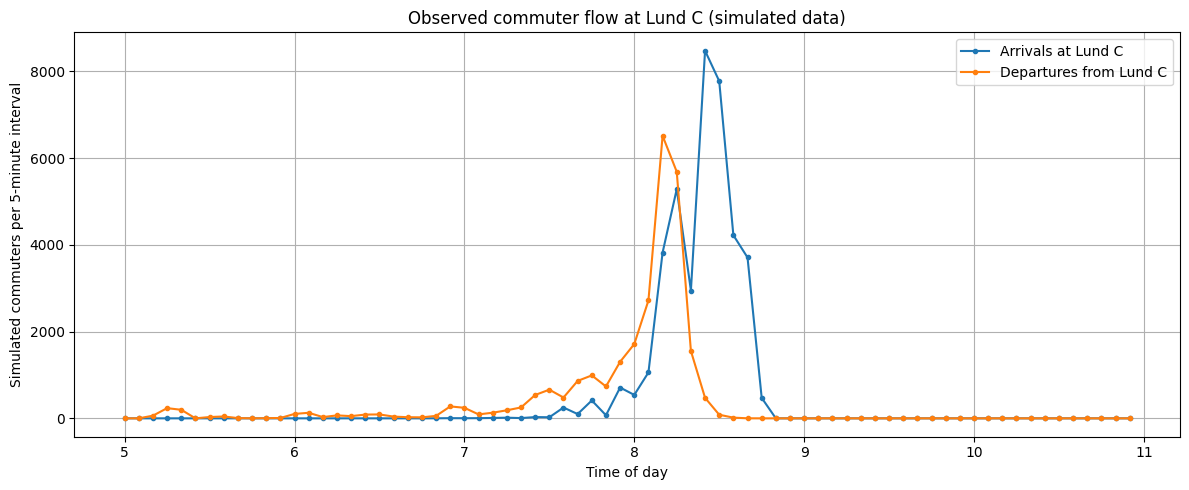

In [71]:
fig, ax = plt.subplots(figsize=(12, 5))

for direction, label in [("arrive", "Arrivals at Lund C"), ("leave", "Departures from Lund C")]:
    subset = counts[counts["commute_type"] == direction]
    ax.plot(subset["bin_minute"] / 60, subset["count"], marker=".", linewidth=1.5, label=label)

ax.set_xlabel("Time of day")
ax.set_ylabel("Simulated commuters per 5-minute interval")
ax.set_title("Observed commuter flow at Lund C (simulated data)")
ax.grid()
ax.legend()
plt.tight_layout()
plt.show()

## Fitting a simple Poisson regression

The response is a count, so a Poisson regression is a reasonable first model. A spline lets the expected count rise and fall over the morning without forcing a straight-line trend.

In [72]:
def log_likelihood_poisson_glm(params, X, y):
    eta = X @ params
    lam = np.exp(np.clip(eta, -30, 30))

    log_lik = np.sum(y * eta - lam - gammaln(y + 1))
    return -log_lik

In [73]:
models_custom = {}
predictions_custom = []

counts["hour"] = counts["bin_minute"] / 60

for direction in ["arrive", "leave"]:

    d = counts[counts["commute_type"] == direction].copy()

    # Create the spline design matrix
    X = np.asarray(
        dmatrix("bs(hour, df=6, degree=3)", data=d)
    )
    y = d["count"].to_numpy(dtype=float)

    # Initial parameter values
    initial_beta = np.zeros(X.shape[1])
    initial_beta[0] = np.log(y.mean() + 1e-5)

    # Fit the Poisson regression
    result = minimize(
        log_likelihood_poisson_glm,
        initial_beta,
        args=(X, y),
        method="BFGS"
    )

    beta_hat = result.x

    models_custom[direction] = {
        "beta": beta_hat,
        "success": result.success
    }

    print(f"{direction.capitalize()} model converged: {result.success}")

    # Calculate predicted counts
    eta_hat = X @ beta_hat
    pred_mean = np.exp(np.clip(eta_hat, -30, 30))

    # Approximate confidence intervals
    cov_matrix = np.asarray(result.hess_inv)
    se_linear = np.sqrt(np.clip(np.sum((X @ cov_matrix) * X, axis=1), 0, None))

    pred = d[["bin_minute", "time", "hour"]].copy()
    pred["observed"] = y
    pred["predicted"] = pred_mean
    pred["lower_95"] = np.exp(
        np.clip(eta_hat - 1.96 * se_linear, -30, 30)
    )
    pred["upper_95"] = np.exp(
        np.clip(eta_hat + 1.96 * se_linear, -30, 30)
    )
    pred["commute_type"] = direction

    predictions_custom.append(pred)

# Combine predictions for both directions
predictions_custom = pd.concat(
    predictions_custom, ignore_index=True
)

predictions_custom.head()


Arrive model converged: False
Leave model converged: False


,bin_minute,time,hour,observed,predicted,lower_95,upper_95,commute_type
0,300,05:00,5.000000,0.0,1.715657e-09,7.741276e-11,3.802317e-08,arrive
1,305,05:05,5.083333,0.0,2.763913e-13,9.357623e-14,5.242947e-11,arrive
2,310,05:10,5.166667,0.0,9.357623e-14,9.357623e-14,2.839827e-13,arrive
3,315,05:15,5.250000,0.0,9.357623e-14,9.357623e-14,9.357623e-14,arrive
4,320,05:20,5.333333,0.0,9.357623e-14,9.357623e-14,9.357623e-14,arrive


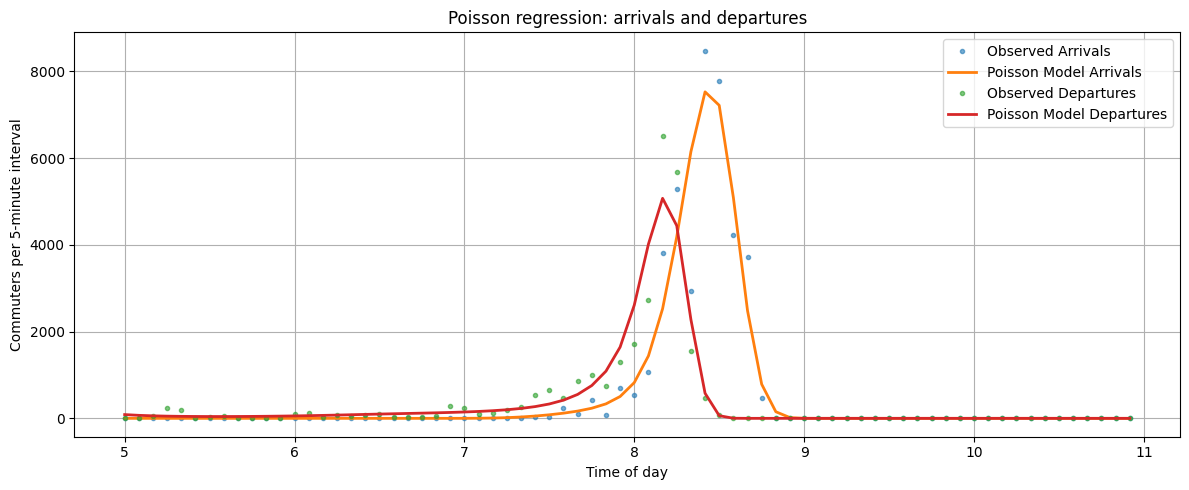

In [74]:
fig, ax = plt.subplots(figsize=(12, 5))

for direction, label in [("arrive", "Arrivals"), ("leave", "Departures")]:
    pred = predictions_custom[
        predictions_custom["commute_type"] == direction
    ]

    ax.plot(pred["hour"], pred["observed"], ".", alpha=0.6, label=f"Observed {label}")

    ax.plot(pred["hour"], pred["predicted"], linewidth=2, label=f"Poisson Model {label}")

ax.set_xlabel("Time of day")
ax.set_ylabel("Commuters per 5-minute interval")
ax.set_title("Poisson regression: arrivals and departures")
ax.grid()
ax.legend()
plt.tight_layout()
plt.show()


## Identifying rush-hour peaks

We report both the busiest observed five-minute interval and the interval with the largest fitted mean. The model can smooth isolated spikes, so the two peak times may differ.

In [75]:

def peak_summary(frame, value_col):
    idx = frame[value_col].idxmax()
    row = frame.loc[idx]

    return {
        "peak_time": row["time"],
        "commuters_per_5min": round(float(row[value_col]), 1),
    }


rows = []

directions = ["arrive", "leave"]

for direction in directions:

    p = predictions_custom[
        predictions_custom["commute_type"] == direction
    ].copy()

    # Highest observed count
    observed_peak = peak_summary(p, "observed")

    # Highest predicted count from the Poisson model
    fitted_peak = peak_summary(p, "predicted")

    # Confidence interval at the fitted peak
    fitted_idx = p["predicted"].idxmax()
    fitted_row = p.loc[fitted_idx]

    rows.append({
        "direction": (
            "Arrivals at Lund C"
            if direction == "arrive"
            else "Departures from Lund C"
        ),
        "busiest_observed_interval": observed_peak["peak_time"],
        "observed_count": observed_peak["commuters_per_5min"],
        "highest_fitted_interval": fitted_peak["peak_time"],
        "fitted_mean_count": fitted_peak["commuters_per_5min"],
        "lower_95": round(float(fitted_row["lower_95"]), 1),
        "upper_95": round(float(fitted_row["upper_95"]), 1),
    })


peak_table = pd.DataFrame(rows)

peak_table


,direction,busiest_observed_interval,observed_count,highest_fitted_interval,fitted_mean_count,lower_95,upper_95
0,Arrivals at Lund C,08:25,8475.0,08:25,7526.5,7443.6,7610.3
1,Departures from Lund C,08:10,6514.0,08:10,5072.3,4985.3,5160.9
